In [ ]:
import kagglehub

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files: ", path)

import os

csv_file_path = os.path.join(path, "creditcard.csv")

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files:  /kaggle/input/creditcardfraud


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(csv_file_path)

In [ ]:
print(df.head())
print("Shape: ", df.shape)
print("\nInfo:\n", df.info())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [ ]:
print(df.isna().sum())

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [ ]:
X = df.drop(columns = ["Class"])
y = df["Class"]

In [ ]:
print("Training Dataset Shape: ", X.shape)
print("\nTesting Dataset Shape: ", y.shape)

Training Dataset Shape:  (284807, 30)

Testing Dataset Shape:  (284807,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(n_estimators = 100,
                          learning_rate = 0.1,
                          max_depth = 3,
                          objective = 'binary:logistic',
                          eval_metric = 'logloss',
                          n_jobs = -1)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve, classification_report

In [ ]:
print("Classification Report:\n", classification_report(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.87      0.78      0.82        98

    accuracy                           1.00     56962
   macro avg       0.94      0.89      0.91     56962
weighted avg       1.00      1.00      1.00     56962



In [ ]:
roc_auc_xgb = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score (XGB Classifier): ", roc_auc_xgb)

ROC-AUC Score (XGB Classifier):  0.9490332465287747


In [ ]:
thresholds = np.array([0.2, 0.3, 0.5, 0.7, 0.9])

for i in thresholds:
  y_pred_threshold = (y_prob >= i).astype(int)
  print(f"Threshold: {i}")
  print("ROC-AUC Score (XGB Classifier): ", roc_auc_score(y_test, y_prob))
  print("\n")

Threshold: 0.2
ROC-AUC Score (XGB Classifier):  0.9490332465287747


Threshold: 0.3
ROC-AUC Score (XGB Classifier):  0.9490332465287747


Threshold: 0.5
ROC-AUC Score (XGB Classifier):  0.9490332465287747


Threshold: 0.7
ROC-AUC Score (XGB Classifier):  0.9490332465287747


Threshold: 0.9
ROC-AUC Score (XGB Classifier):  0.9490332465287747




In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


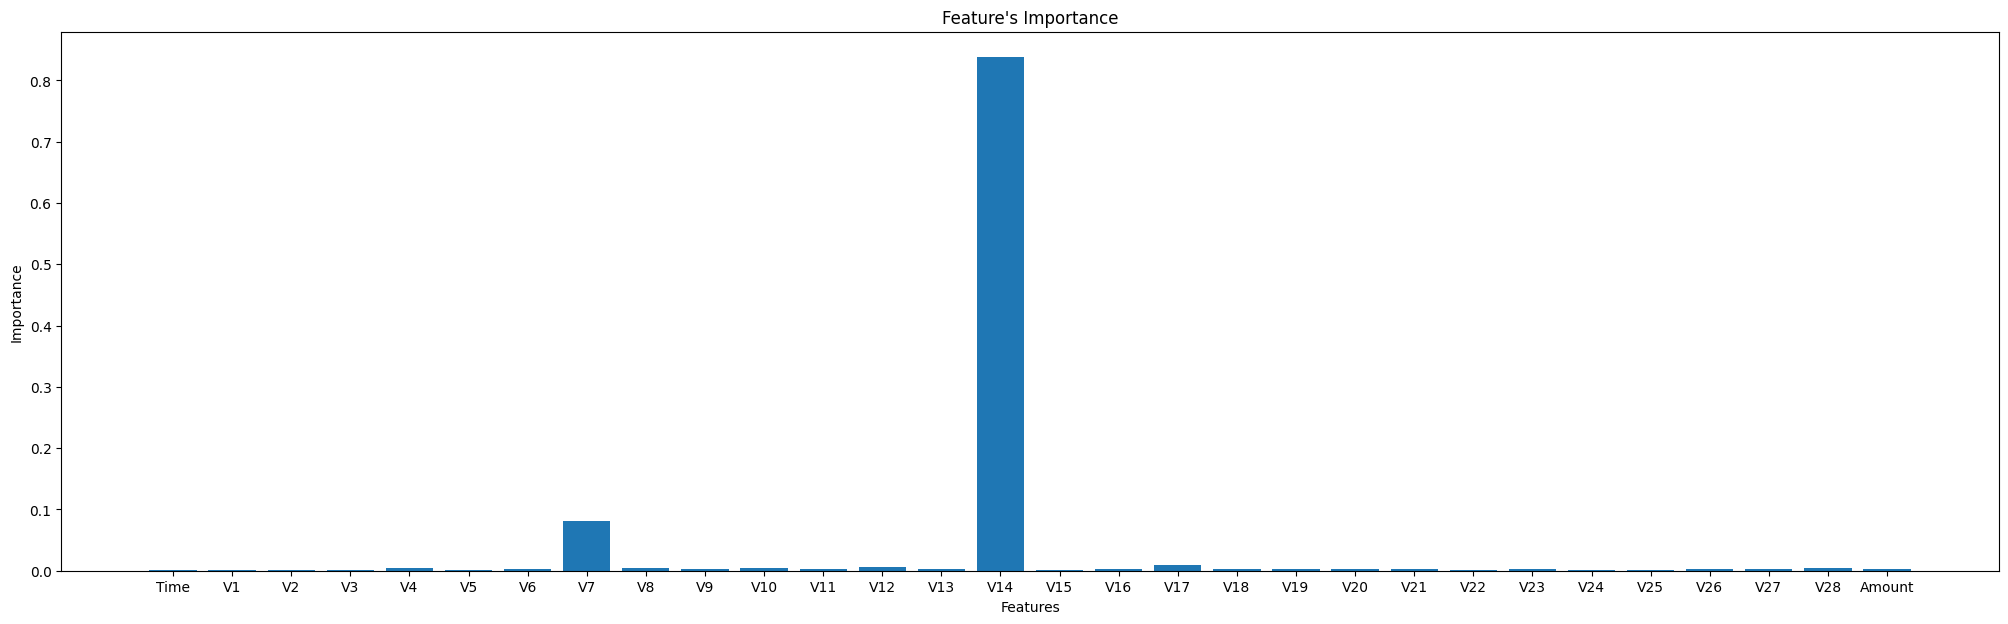

In [ ]:
columns = X.columns.tolist()
print(columns)

importance = xgb_model.feature_importances_

plt.figure(figsize = (25, 7))
plt.bar(columns, importance)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature's Importance")
plt.show()

In [ ]:
from sklearn.svm import SVC

In [ ]:
svm_model = SVC(kernel = 'rbf', C = 1.0, max_iter = 1000, gamma = 'scale', random_state = 42)

svm_model.fit(X_train_scaled, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


SVC(max_iter=1000, random_state=42)

In [ ]:
y_pred_svm = svm_model.predict(X_test_scaled)

In [ ]:
print("Classification Report (SVM MODEL):\n", classification_report(y_test, y_pred_svm))

Classification Report (SVM MODEL):
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.70      0.81        98

    accuracy                           1.00     56962
   macro avg       0.98      0.85      0.91     56962
weighted avg       1.00      1.00      1.00     56962



In [ ]:
roc_auc_svm = roc_auc_score(y_test, y_pred_svm)
print("ROC-AUC SCORE (SVM MODEL): ", roc_auc_svm)

ROC-AUC SCORE (SVM MODEL):  0.8520144375983371


In [ ]:
import matplotlib.pyplot as plt

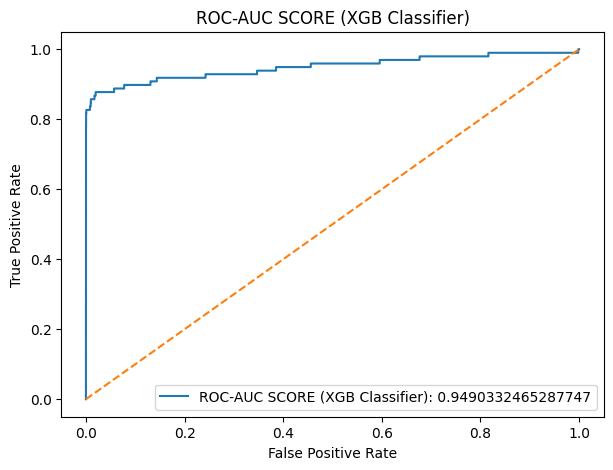

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize = (7, 5))
plt.plot(fpr, tpr, label = f"ROC-AUC SCORE (XGB Classifier): {roc_auc_xgb}")
plt.plot([0, 1], [0, 1], linestyle = "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC SCORE (XGB Classifier)")
plt.legend()
plt.show()

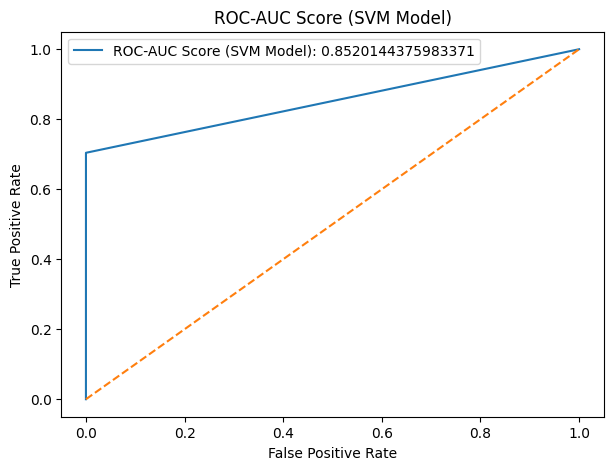

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_pred_svm)

plt.figure(figsize = (7, 5))
plt.plot(fpr, tpr, label = f"ROC-AUC Score (SVM Model): {roc_auc_svm}")
plt.plot([0, 1], [0, 1], linestyle = "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Score (SVM Model)")
plt.legend()
plt.show()